# 8 Multiresolution Analysis (MRA)

## 8.3 1D Multiresolution Analysis
### 8.3.3 PyWavelets 1D Implementations

**2. Installation and Setup**

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import pywt
from scipy import signal
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(42)

**3. Basic 1D MRA Functions**


In [2]:
def multilevel_1d_mra(data, wavelet='db4', levels=3, mode='symmetric', transform='swt'):
    """
    Perform multilevel 1D MRA analysis
    
    Parameters:
    -----------
    data : array_like
        Input 1D signal
    wavelet : str or Wavelet object
        Wavelet to use for decomposition
    levels : int
        Number of decomposition levels
    mode : str
        Signal extension mode (for DWT only)
    transform : str
        'swt' for Stationary WT or 'dwt' for Discrete WT
        
    Returns:
    --------
    mra_components : list
        MRA reconstruction components [A_n, D_n, D_n-1, ..., D_1]
    """
    return pywt.mra(data, wavelet=wavelet, level=levels, 
                   mode=mode, transform=transform)

def analyze_1d_mra_energy(mra_components):
    """Analyze energy distribution across MRA components"""
    energies = [np.sum(component**2) for component in mra_components]
    total_energy = sum(energies)
    energy_percentages = [100 * e / total_energy for e in energies]
    
    return {
        'energies': energies,
        'percentages': energy_percentages,
        'total_energy': total_energy
    }

**4. Example: Synthetic Signal Decomposition**

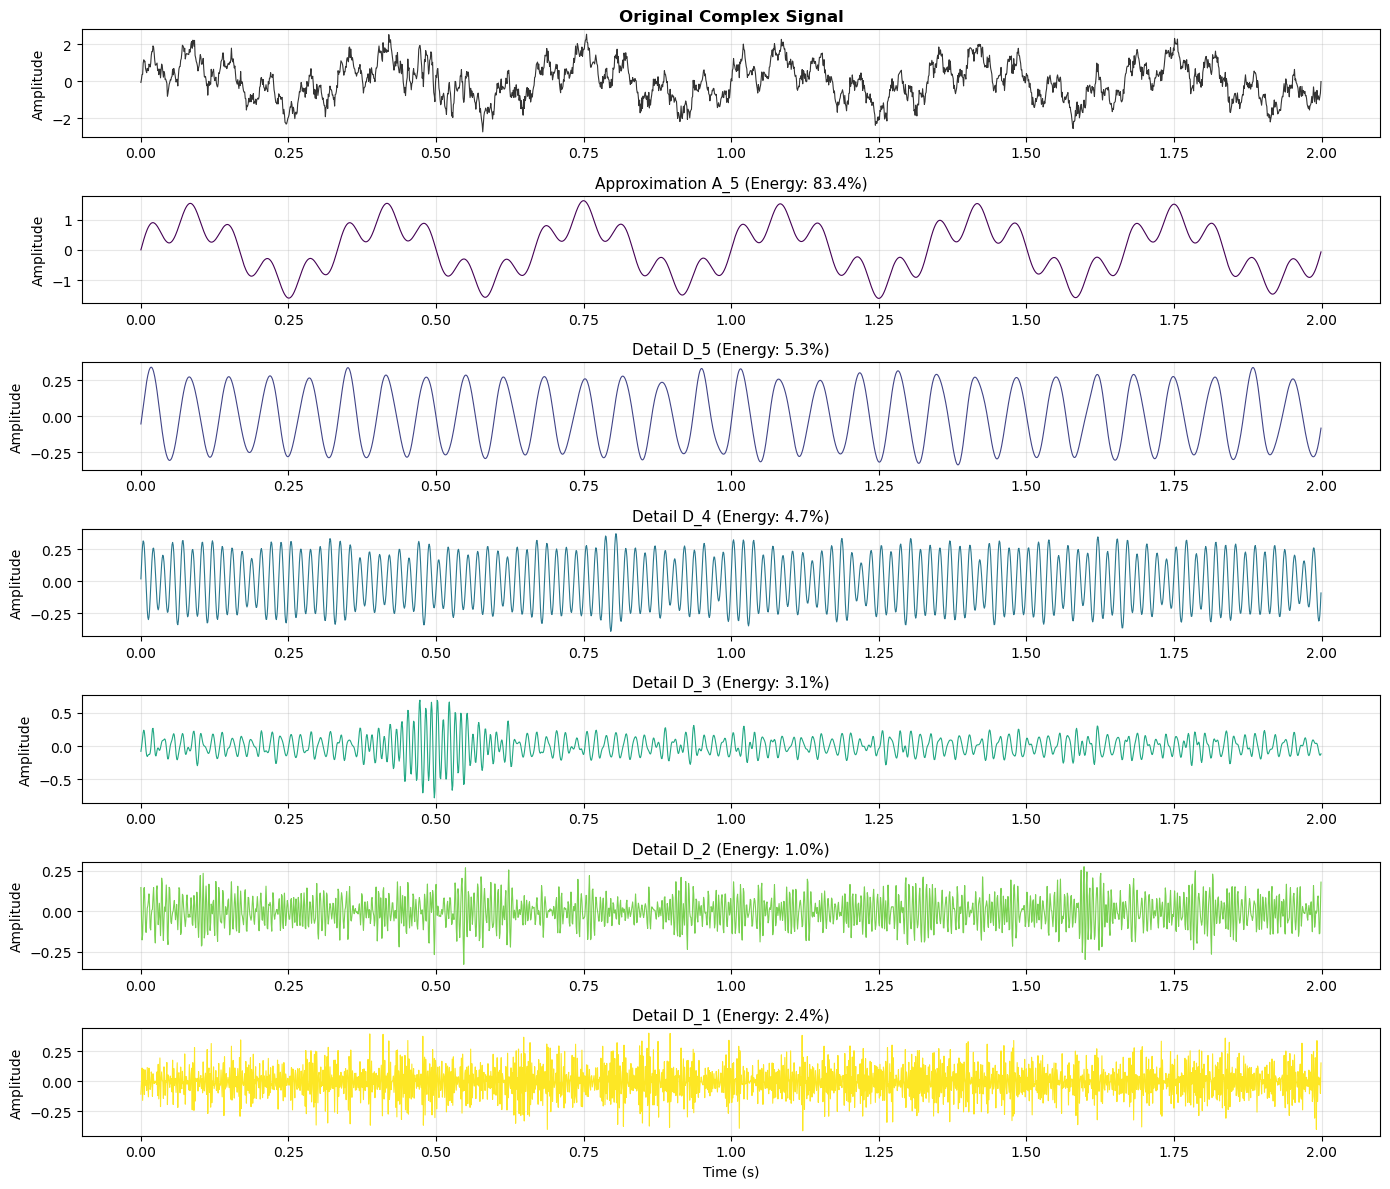

Maximum reconstruction error: 1.78e-15
=== MRA Energy Analysis ===
Total Signal Energy: 1574.438176

Energy Distribution:
--------------------------------------------------
=== MRA Energy Analysis ===
Total Signal Energy: 1574.438176

Energy Distribution:
--------------------------------------------------
Approximation A_5   :  1313.309771 ( 83.41%)
Detail D_5          :    83.916987 (  5.33%)
Detail D_4          :    73.863668 (  4.69%)
Detail D_3          :    49.440656 (  3.14%)
Detail D_2          :    15.933600 (  1.01%)
Detail D_1          :    37.973495 (  2.41%)


In [ ]:
# Create complex test signal
t = np.linspace(0, 2, 2048, endpoint=False)
signal_test = (
    np.sin(2 * np.pi * 3 * t) +                    # Low frequency
    0.8 * np.sin(2 * np.pi * 15 * t) +             # Medium frequency  
    0.4 * np.sin(2 * np.pi * 60 * t) +             # High frequency
    0.6 * np.exp(-((t-0.5)/0.1)**2) * np.sin(2 * np.pi * 100 * t) +  # Transient
    0.2 * np.random.randn(len(t))                  # Noise
)

# Perform 5-level MRA
wavelet = 'db8'
mode='periodization' # 
transform='swt'
mra_components = multilevel_1d_mra(signal_test, wavelet, levels, mode, transform)

# Analyze energy distribution
energy_analysis = analyze_1d_mra_energy(mra_components)

# Visualization
fig, axes = plt.subplots(levels + 2, 1, figsize=(14, 12))

# Original signal
axes[0].plot(t, signal_test, 'k-', linewidth=0.8, alpha=0.8)
axes[0].set_title('Original Complex Signal', fontsize=12, fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].set_ylabel('Amplitude')

# MRA components
component_names = [f'Approximation A_{levels}'] + \
                 [f'Detail D_{levels-i+1}' for i in range(1, levels+1)]

colors = plt.cm.viridis(np.linspace(0, 1, levels+1))

for i, (component, name, color) in enumerate(zip(mra_components, component_names, colors)):
    axes[i+1].plot(t, component, color=color, linewidth=0.8)
    energy_pct = energy_analysis['percentages'][i]
    axes[i+1].set_title(f'{name} (Energy: {energy_pct:.1f}%)', fontsize=11)
    axes[i+1].grid(True, alpha=0.3)
    axes[i+1].set_ylabel('Amplitude')

axes[-1].set_xlabel('Time (s)')
plt.tight_layout()
plt.savefig('./imagesoutput/mra_components.png', dpi=300)
plt.show()

# Verify perfect reconstruction
reconstructed = np.sum(mra_components, axis=0)
reconstruction_error = np.max(np.abs(signal_test - reconstructed))
print(f"Maximum reconstruction error: {reconstruction_error:.2e}")

# Print energy information
print("=== MRA Energy Analysis ===")
print(f"Total Signal Energy: {energy_analysis['total_energy']:.6f}")
print("\nEnergy Distribution:")
print("-" * 50)

# Print energy information
print("=== MRA Energy Analysis ===")
print(f"Total Signal Energy: {energy_analysis['total_energy']:.6f}")
print("\nEnergy Distribution:")
print("-" * 50)

# component_names = [f'Approximation A_{levels}'] + [f'Detail D_{levels-i+1}' for i in range(1, levels+1)]
component_names_console = [f'Approximation A{get_unicode_subscript(levels)}'] + \
                             [f'Detail D{get_unicode_subscript(levels-i+1)}' for i in range(1, levels+1)]

for i, (name, energy, percentage) in enumerate(zip(component_names, 
                                                   energy_analysis['energies'], 
                                                   energy_analysis['percentages'])):
    print(f"{name:<20}: {energy:>12.6f} ({percentage:>6.2f}%)")


## 8.4 2D Multiresolution Analysis
### 8.4.3 PyWavelets 2D Implementation
**2. Perform Multilevel 2D MRA Analysis on images**

In [1]:
def multilevel_2d_mra(image, wavelet='db4', levels=3, mode='symmetric'):
    """
    Perform multilevel 2D MRA analysis on images
    
    Parameters:
    -----------
    image : array_like
        Input 2D image
    wavelet : str or Wavelet object
        Wavelet to use for decomposition
    levels : int
        Number of decomposition levels
    mode : str
        Signal extension mode
        
    Returns:
    --------
    coeffs : list
        Wavelet coefficients [cA_n, (cH_n, cV_n, cD_n), ..., (cH_1, cV_1, cD_1)]
    """
    return pywt.wavedec2(image, wavelet, level=levels, mode=mode)

def visualize_2d_mra(coeffs, figsize=(15, 10)):
    """Visualize 2D MRA decomposition coefficients"""
    levels = len(coeffs) - 1
    
    fig, axes = plt.subplots(2, levels + 1, figsize=figsize)
    if levels == 0:
        axes = axes.reshape(2, 1)
    
    # Approximation
    axes[0, 0].imshow(coeffs[0], cmap='gray')
    axes[0, 0].set_title(f'Approximation A_{levels}')
    axes[0, 0].axis('off')
    
    # Empty subplot for symmetry
    axes[1, 0].axis('off')
    
    # Detail coefficients
    for i in range(1, levels + 1):
        level_idx = levels - i + 1
        cH, cV, cD = coeffs[i]
        
        # Horizontal details
        axes[0, i].imshow(cH, cmap='gray')
        axes[0, i].set_title(f'Horizontal D_{level_idx}^H')
        axes[0, i].axis('off')
        
        # Vertical and Diagonal details
        if i < levels:
            axes[1, i].imshow(cV, cmap='gray')
            axes[1, i].set_title(f'Vertical D_{level_idx}^V')
        else:
            # Show both vertical and diagonal for the finest level
            axes[1, i].imshow(np.hstack([cV, cD]), cmap='gray')
            axes[1, i].set_title(f'Vertical & Diagonal D_{level_idx}^{{V,D}}')
        axes[1, i].axis('off')
    
    plt.tight_layout()
    return fig

def reconstruct_2d_mra(coeffs, wavelet='db4', mode='symmetric'):
    """Reconstruct image from 2D MRA coefficients"""
    return pywt.waverec2(coeffs, wavelet, mode)

**3. Example: 2D Image Analysis**

Loading real image: ./data/forest-fire.webp


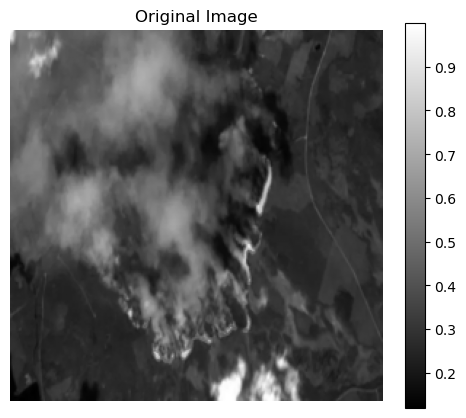

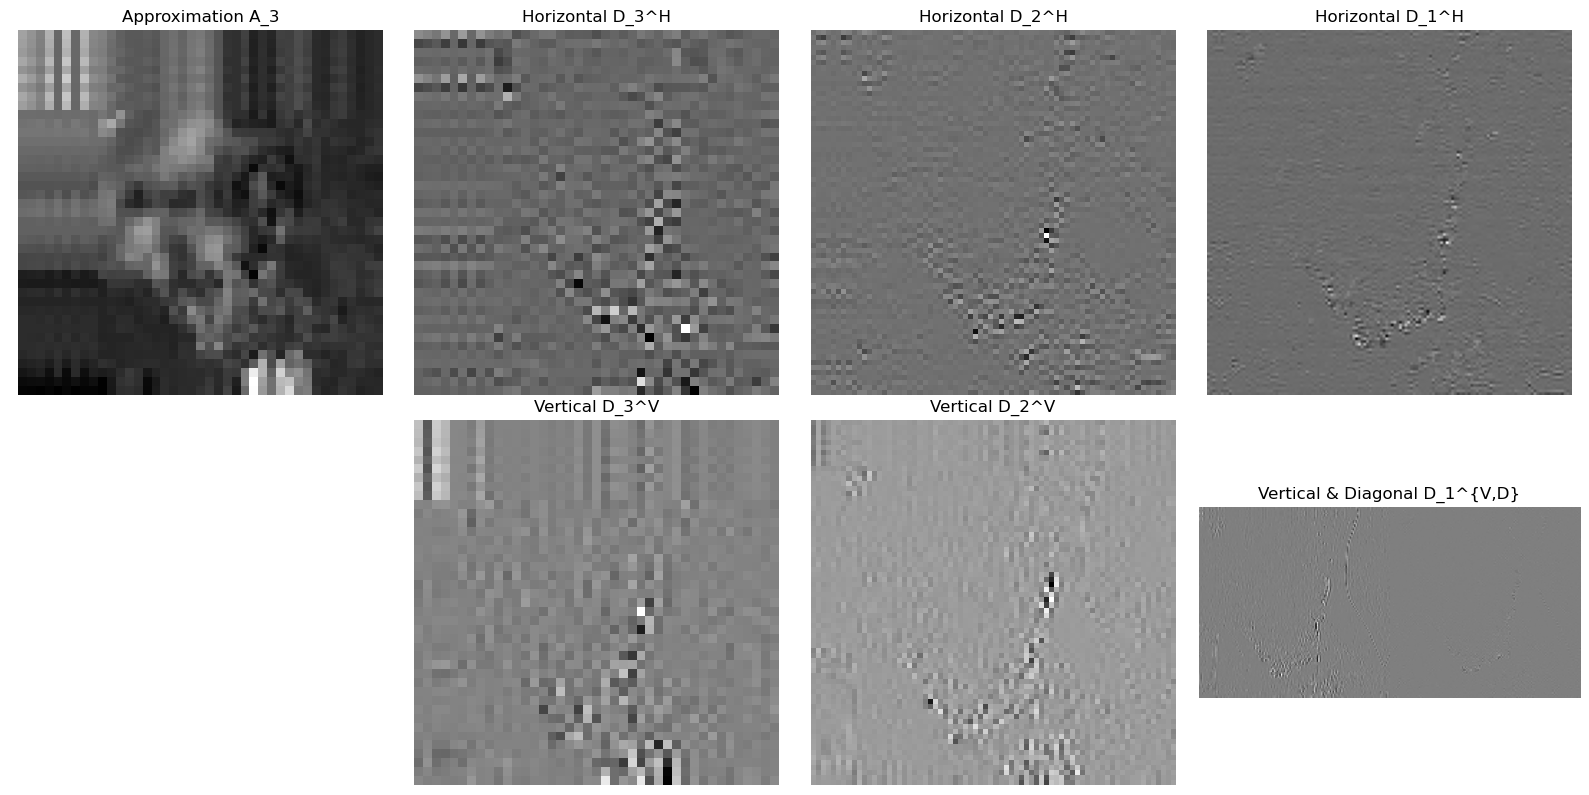

2D MRA Coefficient Statistics:
   level      component      energy  max_val     std
0      3  Approximation  17409.9881   8.4783  1.1049
1      3     Horizontal     16.6538   0.8756  0.0995
2      3       Vertical     80.9825   1.6783  0.2194
3      3       Diagonal      9.0230   0.6331  0.0733
4      2     Horizontal      4.6049   0.4060  0.0298
5      2       Vertical     19.9731   0.7736  0.0621
6      2       Diagonal      1.8649   0.1727  0.0190
7      1     Horizontal      0.7250   0.1073  0.0064
8      1       Vertical      4.1643   0.1988  0.0153
9      1       Diagonal      0.1988   0.0666  0.0034

2D Maximum reconstruction error: 1.22e-15
2D Mean error: 1.35e-16
2D RMSE: 1.78e-16


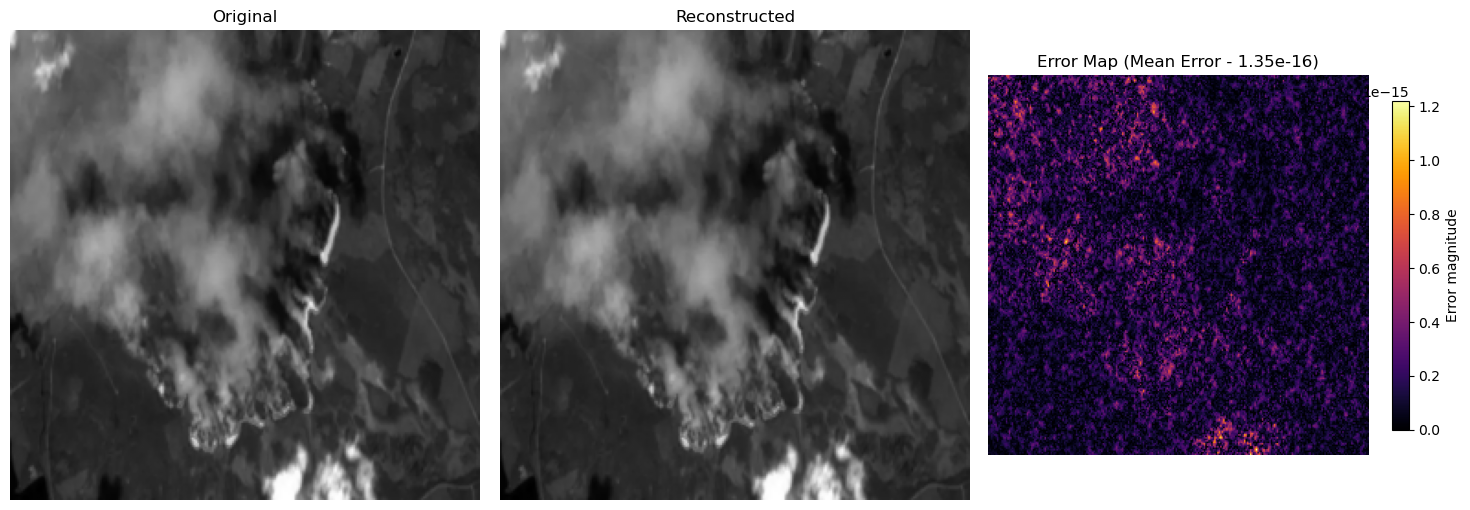

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from skimage import io, color, img_as_float
from skimage.transform import resize

# -----------------------------
# Load a real data or Synthetic test image generator
# -----------------------------

def load_or_create_image(path: str = "./data/forest-fire.webp", size: int = 256, seed: int = 42) -> np.ndarray:
    """
    Load a real image if available; otherwise, create a synthetic test image.

    Parameters
    ----------
    path : str, optional
        Path to the real image file, by default "./data/forest-fire.webp".
    size : int, optional
        Desired image size (square), by default 256.
    seed : int, optional
        Random seed for reproducibility in synthetic data, by default 42.

    Returns
    -------
    np.ndarray
        Grayscale float image of shape (size, size).
    """
    try:
        if os.path.exists(path):
            print(f"Loading real image: {path}")
            img = io.imread(path)

            # Convert to grayscale if RGB
            if img.ndim == 3:
                img = color.rgb2gray(img)

            img = img_as_float(img)

            # Resize to desired size
            return resize(img, (size, size), anti_aliasing=True)

        else:
            raise FileNotFoundError

    except Exception as e:
        print(f"⚠️ Could not load real image ({e}), using synthetic test image instead.")

        # Create synthetic image
        np.random.seed(seed)
        x, y = np.meshgrid(np.linspace(-1, 1, size), np.linspace(-1, 1, size))
        r = np.sqrt(x**2 + y**2)

        image = np.zeros((size, size), dtype=np.float32)

        # Radial pattern
        image += 0.5 * np.exp(-5 * r**2) * np.cos(20 * r)

        # Horizontal stripes
        image[: size // 4, :] += 0.3 * np.sin(20 * np.pi * x[: size // 4, :])

        # Vertical block
        image[size // 2 : 3 * size // 4, size // 4 : size // 2] += 0.8

        # Diagonal texture
        diag_tex = 0.4 * np.sin(15 * (x + y))
        image[3 * size // 4 :, 3 * size // 4 :] += diag_tex[3 * size // 4 :, 3 * size // 4 :]

        # Add Gaussian noise
        image += 0.1 * np.random.randn(size, size)

        return image


# -----------------------------
# Coefficient statistics analyzer
# -----------------------------
def analyze_2d_coeffs(coeffs: list) -> pd.DataFrame:
    """Analyze statistics of 2D wavelet coefficients."""
    stats = []

    # Approximation
    approx = coeffs[0]
    stats.append({
        "level": len(coeffs) - 1,
        "component": "Approximation",
        "energy": np.sum(approx**2),
        "max_val": np.max(np.abs(approx)),
        "std": np.std(approx),
    })

    # Details
    for i, (cH, cV, cD) in enumerate(coeffs[1:], start=1):
        level = len(coeffs) - i
        for comp, data in zip(["Horizontal", "Vertical", "Diagonal"], [cH, cV, cD]):
            stats.append({
                "level": level,
                "component": comp,
                "energy": np.sum(data**2),
                "max_val": np.max(np.abs(data)),
                "std": np.std(data),
            })

    return pd.DataFrame(stats)


# -----------------------------
# Example workflow
# -----------------------------
if __name__ == "__main__":
    # Load image (real or synthetic)
    image = load_or_create_image("./data/forest-fire.webp", size=256)

    # Perform 3-level 2D MRA
    levels = 3
    wavelet = "db6"
    coeffs_2d = multilevel_2d_mra(image, wavelet, levels)

    # Show original
    # plt.figure(figsize=(6, 5))
    # plt.imshow(image, cmap="gray")
    # plt.title("Original Image")
    # plt.axis("off")
    # plt.colorbar()
    # plt.savefig('./output/2dmra_original_image.png', dpi=300)
    # plt.show()

    # Visualize decomposition
    fig = visualize_2d_mra(coeffs_2d, figsize=(16, 8))
    plt.savefig('./output/2dmra_decomposition.png', dpi=300)
    plt.show()

    # Analyze coefficient statistics
    df_stats = analyze_2d_coeffs(coeffs_2d)
    print("2D MRA Coefficient Statistics:")
    print(df_stats.round(4))

    # Reconstruct and verify
reconstructed = reconstruct_2d_mra(coeffs_2d, wavelet)
error_map = np.abs(image - reconstructed)

# Error metrics
max_error = np.max(error_map)
mean_error = np.mean(error_map)
rmse = np.sqrt(np.mean((image - reconstructed) ** 2))

print(f"\n2D Maximum reconstruction error: {max_error:.2e}")
print(f"2D Mean error: {mean_error:.2e}")
print(f"2D RMSE: {rmse:.2e}")

# Compare reconstruction visually
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(reconstructed, cmap="gray")
axes[1].set_title("Reconstructed")
axes[1].axis("off")

im = axes[2].imshow(error_map, cmap="inferno")
axes[2].set_title(f"Error Map (Mean Error - {mean_error:.2e})")
axes[2].axis("off")

# Add colorbar
cbar = fig.colorbar(im, ax=axes[2], shrink=0.7)
cbar.set_label("Error magnitude")

# Overlay extra error values on error map
#error_text = f"Max: {max_error:.2e}\nRMSE: {rmse:.2e}"
# axes[2].text(
#     0.5, -0.1, error_text,
#     color="white", fontsize=12, ha="center", va="top",
#     transform=axes[2].transAxes,
#     bbox=dict(facecolor="black", alpha=0.6, edgecolor="none", boxstyle="round,pad=0.3")
# )

plt.tight_layout()
plt.savefig('./outputs/2dmra_reconstruction_and_error.png', dpi=300)
plt.show()


## 8.5 N-D Multiresolution Analysis
### 8.5.2 PyWavelets N-D Implementation

**2. Perform multilevel N-D MRA Analysis**

In [1]:
# --- N-D MRA functions ---
def multilevel_nd_mra(data, wavelet='db4', levels=2, mode='symmetric', axes=None):
    """
    Perform multilevel N-D MRA analysis
    
    Parameters:
    -----------
    data : array_like
        Input N-D data
    wavelet : str or Wavelet object
        Wavelet to use for decomposition
    levels : int
        Number of decomposition levels
    mode : str
        Signal extension mode
    axes : None or sequence of ints
        Axes over which to compute the DWT
        
    Returns:
    --------
    coeffs : list
        N-D wavelet coefficients
    """
    return pywt.wavedecn(data, wavelet, level=levels, mode=mode, axes=axes)



def reconstruct_nd_mra(coeffs, wavelet='db4', mode='symmetric', axes=None):
    """Reconstruct N-D data from MRA coefficients"""
    return pywt.waverecn(coeffs, wavelet, mode=mode, axes=axes)

def analyze_nd_coeffs(coeffs, data_shape):
    """Analyze N-D wavelet coefficient structure"""
    analysis = {
        'total_levels': len(coeffs) - 1,
        'original_shape': data_shape,
        'coeffs_info': []
    }
    
    # Approximation coefficients
    approx = coeffs[0]
    analysis['coeffs_info'].append({
        'level': len(coeffs) - 1,
        'type': 'approximation',
        'shape': approx.shape,
        'energy': np.sum(approx**2),
        'compression_ratio': np.prod(data_shape) / np.prod(approx.shape)
    })
    
    # Detail coefficients
    for level_idx in range(1, len(coeffs)):
        level = len(coeffs) - level_idx
        detail_dict = coeffs[level_idx]
        
        for key, detail_coeffs in detail_dict.items():
            analysis['coeffs_info'].append({
                'level': level,
                'type': f'detail_{key}',
                'shape': detail_coeffs.shape,
                'energy': np.sum(detail_coeffs**2),
                'max_abs': np.max(np.abs(detail_coeffs))
            })
    
    return analysis

# --- Plot decomposition coefficients ---
def isualize_nd_mra(coeffs, cmap='gray'):
    """
    Plot approximation + detail coefficients for each level (2D slices)
    """
    n_levels = len(coeffs) - 1
    plt.figure(figsize=(4*(n_levels+1), 4))
    
    # Approximation
    plt.subplot(1, n_levels+1, 1)
    plt.imshow(coeffs[0], cmap=cmap)
    plt.title(f'Approx Level {n_levels}')
    plt.axis('off')
    
    # Details per level
    for i, detail in enumerate(coeffs[1:]):
        level = n_levels - i
        # Combine all detail directions in one block for visualization
        keys = list(detail.keys())
        block = np.block([[detail[keys[j]] for j in range(len(keys))]])
        plt.subplot(1, n_levels+1, i+2)
        plt.imshow(block, cmap=cmap)
        plt.title(f'Details Level {level}')
        plt.axis('off')
    
    plt.tight_layout()
    return fig

**3. Real-world Example of Multilevel N-D MRA Analysis**

Loaded 3D brain MRI from skimage.data
Data shape: (10, 256, 256)
Data range: [0.000, 51076.000]

Performing 3-level decomposition with db6 wavelet...

3D MRA Coefficient Statistics:
 Level Subband          Shape          Min          Max       Mean
     1     aaa (10, 256, 256)  -22254.1800  165102.6766 10460.3365
     1     aad (10, 256, 256)  -17751.2706   21221.6050    -0.0000
     1     ada (10, 256, 256)  -21119.7343   18665.2952    -0.0000
     1     add (10, 256, 256)   -6818.1565    8667.1755     0.0000
     1     daa (10, 256, 256)  -42365.3166   37049.3238    -0.0000
     1     dad (10, 256, 256)  -10500.8338   12202.3648    -0.0000
     1     dda (10, 256, 256)   -9464.3295   11628.7314    -0.0000
     1     ddd (10, 256, 256)   -3161.2938    2657.3456    -0.0000
     2     aaa (10, 256, 256)  -67230.6527  460704.6083 29586.2996
     2     aad (10, 256, 256)  -33574.6023   32460.8757    -0.0000
     2     ada (10, 256, 256)  -36672.7774   30788.9892    -0.0000
     2     add

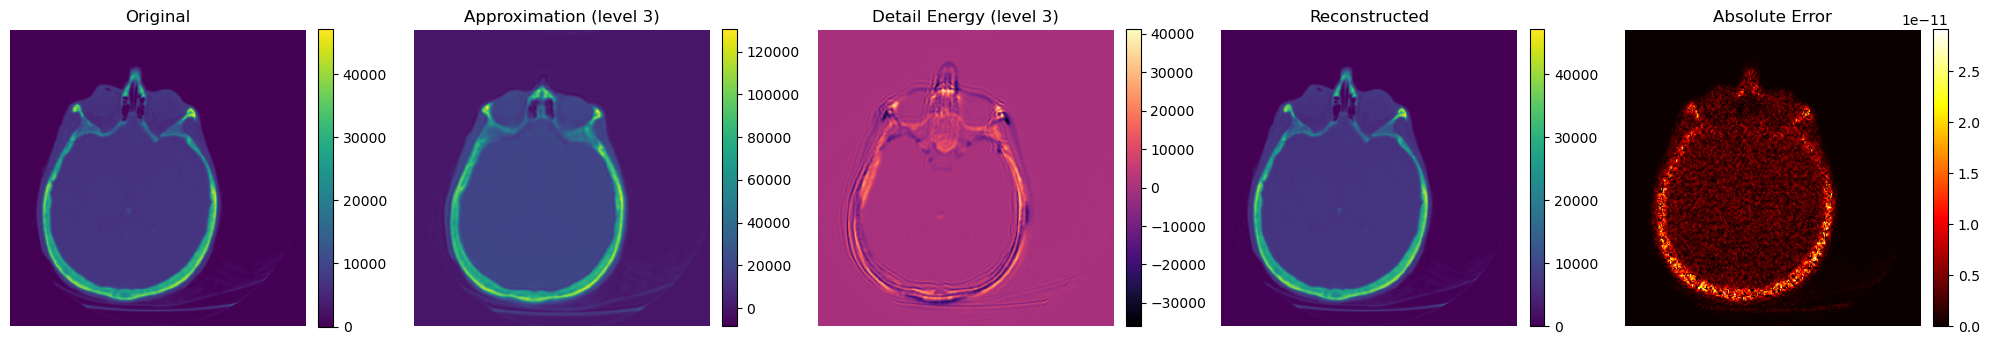

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pywt
import pandas as pd
from skimage import data

# ------------------------------------------------------------------
# 0. Attempt to load real 3D volume, else create synthetic
# ------------------------------------------------------------------
try:
    volume_3d = data.brain()  # 3D MRI, shape (256,256,109)
    print("Loaded 3D brain MRI from skimage.data")
except:
    print("Failed to load real 3D data, creating synthetic volume...")
    def create_3d_volume(size=64):
        x, y, z = np.meshgrid(np.linspace(0, 1, size),
                              np.linspace(0, 1, size),
                              np.linspace(0, 1, size))
        r = np.sqrt((x-0.5)**2 + (y-0.5)**2 + (z-0.5)**2)
        v = np.sin(2*np.pi*3*r) * np.exp(-8*r**2) + 0.1*np.random.randn(size,size,size)
        return np.clip(v, 0, 1)
    volume_3d = create_3d_volume(64)

print(f"Data shape: {volume_3d.shape}")
print(f"Data range: [{volume_3d.min():.3f}, {volume_3d.max():.3f}]")

# ------------------------------------------------------------------
# 1. Multilevel N-D wavelet decomposition and reconstruction
# ------------------------------------------------------------------
def multilevel_nd_mra(data, wavelet='db6', levels=3):
    coeffs = []
    arr = data.copy()
    for lvl in range(levels):
        # Decompose along all axes
        coeff = pywt.swtn(arr, wavelet=wavelet, level=1, axes=(0,1,2))[0]
        arr = coeff['aaa']  # approximation for next level
        coeffs.append(coeff)
    return coeffs

def reconstruct_nd_mra(coeffs, wavelet='db6'):
    arr = coeffs[-1]['aaa']
    for coeff in reversed(coeffs):
        coeff_copy = coeff.copy()
        coeff_copy['aaa'] = arr
        arr = pywt.iswtn([coeff_copy], wavelet=wavelet)
    return arr

def analyze_nd_coeffs(coeffs, shape):
    info = []
    for lvl, coeff in enumerate(coeffs):
        for key, arr in coeff.items():
            info.append({'Level': lvl+1, 'Subband': key, 'Shape': arr.shape,
                         'Min': arr.min(), 'Max': arr.max(), 'Mean': arr.mean()})
    return {'coeffs_info': info}

print("\nPerforming 3-level decomposition with db6 wavelet...")
coeffs_3d = multilevel_nd_mra(volume_3d, wavelet='db6', levels=3)
recon_3d = reconstruct_nd_mra(coeffs_3d, wavelet='db6')

# ------------------------------------------------------------------
# 2. Coefficient statistics
# ------------------------------------------------------------------
analysis = analyze_nd_coeffs(coeffs_3d, volume_3d.shape)
df_stats = pd.DataFrame(analysis['coeffs_info'])
print("\n3D MRA Coefficient Statistics:")
print(df_stats.round(4).to_string(index=False))

# ------------------------------------------------------------------
# 3. Reconstruction quality
# ------------------------------------------------------------------
max_err = np.max(np.abs(volume_3d - recon_3d))
mean_err = np.mean(np.abs(volume_3d - recon_3d))
rmse = np.sqrt(np.mean((volume_3d - recon_3d)**2))
print(f"\n3D Max-error: {max_err:.2e}")
print(f"3D Mean-error: {mean_err:.2e}")
print(f"3D RMSE:      {rmse:.2e}")

# ------------------------------------------------------------------
# 4. Helper: central slice for display
# ------------------------------------------------------------------
def mid_slice(vol):
    return vol[vol.shape[0]//2, :, :]

# ------------------------------------------------------------------
# 5. Five-panel figure
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

# (a) original
im0 = axes[0].imshow(mid_slice(volume_3d), cmap='viridis')
axes[0].set_title("Original")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

# (b) approximation (LLL) at level 3
approx = coeffs_3d[0]['aaa']  # use first level approximation
im1 = axes[1].imshow(mid_slice(approx), cmap='viridis')
axes[1].set_title("Approximation (level 3)")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

# (c) detail-energy at level 3
detail_sum = np.zeros_like(approx)
for key, detail in coeffs_3d[0].items():
    if key != 'aaa':
        detail_sum += detail
im2 = axes[2].imshow(mid_slice(detail_sum), cmap='magma')
axes[2].set_title("Detail Energy (level 3)")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

# (d) reconstructed
im3 = axes[3].imshow(mid_slice(recon_3d), cmap='viridis')
axes[3].set_title("Reconstructed")
plt.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)

# (e) absolute error
error_map = np.abs(volume_3d - recon_3d)
im4 = axes[4].imshow(mid_slice(error_map), cmap='hot')
axes[4].set_title("Absolute Error")
plt.colorbar(im4, ax=axes[4], fraction=0.046, pad=0.04)

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.savefig('./outputs/8.3_3dmra_decomposition.png', dpi=300)
plt.show()
